# CS 436 Final Project: SGD and Momentum

**Names:** Markus Massina and Michael Truong

**Dataset:** CIFAR-10

**Question:** Does adding momentum to SGD change first-layer energy profiles, test accuracy, and training time?

## 1. Setup

Import the libraries and select one device and results folder for the experiment.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from utils import PROJECT_DIR

# prefer an available GPU, with CPU as the fallback
# all final runs must use the same device and machine for comparable timings
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'

# use the repository root so results have one location across notebooks
# section 4 creates this folder when it saves the first run
results_dir = PROJECT_DIR / 'results'

print(f'device: {device}')
print(f'results folder: {results_dir}')

device: cuda
results folder: /content/CS436-FinalProj-Fork/results


## 2. Experiment settings

Compare two momentum settings across three matched seeds while keeping the other training settings fixed.

In [2]:
model_name = 'vgg11_bn'

# each seed gives both optimizers matching initial weights and batch order
seeds = [436, 437, 438]
# zero is ordinary SGD and 0.9 enables momentum for the modified condition
momentums = [0.0, 0.9]

# keep the training budget and learning rate the same for both conditions
num_epochs = 30
batch_size = 256
learning_rate = 0.01

# leave other optimizer options disabled to isolate the momentum change
weight_decay = 0.0
dampening = 0.0
nesterov = False

# use a separate seeded training-image sample for the shared PCA basis
# PCA sampling stays independent of model initialization and batch order
pca_seed = 436
pca_image_count = 10000

# store each seed/momentum pair as a dictionary for the later training loop
# three seeds times two momentum settings gives six configurations
run_settings = []
for seed in seeds:
    for momentum in momentums:
        run_settings.append({
            'seed': seed,
            'momentum': momentum
        })

# preview the configurations without downloading data or training any models
for run_number, settings in enumerate(run_settings, start=1):
    seed = settings['seed']
    momentum = settings['momentum']
    print(f'run {run_number}: seed={seed}, momentum={momentum}, epochs={num_epochs}')

print(f'total training runs: {len(run_settings)}')

run 1: seed=436, momentum=0.0, epochs=30
run 2: seed=436, momentum=0.9, epochs=30
run 3: seed=437, momentum=0.0, epochs=30
run 4: seed=437, momentum=0.9, epochs=30
run 5: seed=438, momentum=0.0, epochs=30
run 6: seed=438, momentum=0.9, epochs=30
total training runs: 6


## 3. CIFAR-10 data and shared PCA

Load CIFAR-10 and compute one shared PCA basis from training images only.

In [3]:
from utils import get_dataloader, get_patch_pca #using functions in utils for consistency


# Seed before the PCA loader
torch.manual_seed(pca_seed)
# Keeping true labels, consistent with the experiments in linear_fit.ipynb and true_vs_random.ipynb
use_random_labels = False
# Loads/builds the test data
test_loader = get_dataloader(use_random_labels, train=False, batch_size=batch_size)
pca_loader = get_dataloader(use_random_labels, train=True, batch_size=batch_size)
# Runs the PCA for all 10,000 images
components, lambdas, num_images = get_patch_pca(pca_loader, num_images=pca_image_count)
print(f'PCA ran with {num_images} images')


PCA ran with 10000 images


## 4. Train the six configurations

Train matched models, measure training time, and save each completed run for later analysis.

In [4]:
import json
import platform
import torchvision
from torch.utils.data import DataLoader
from utils import train_model, get_model, get_first_layer_weights, calc_energy_profile, MODEL_REPO

# reuse the training dataset that section 3 loaded for PCA
train_dataset = pca_loader.dataset
results_dir.mkdir(parents=True, exist_ok=True)

# save the shared PCA basis once so the analysis can reuse it
np.savez(results_dir / 'pca.npz', components=components.numpy(), lambdas=lambdas.numpy())

# record the machine and software, since timings are only comparable on one setup
environment = {
    'machine': platform.node(),
    'platform': platform.platform(),
    'device': device,
    'python': platform.python_version(),
    'torch': torch.__version__,
    'torchvision': torchvision.__version__,
    'model_source': MODEL_REPO
}

results = {}
for settings in run_settings:
    seed = settings['seed']
    momentum = settings['momentum']
    run_file = results_dir / f'seed_{seed}_momentum_{momentum}.json'

    # a saved file marks a finished run, so a restart does not train it again
    if run_file.exists():
        results[(seed, momentum)] = json.loads(run_file.read_text())
        # stop if the saved run used a different training length, such as a short test run
        assert len(results[(seed, momentum)]['history']) == num_epochs, run_file.name
        print(f'loaded {run_file.name}')
        continue

    # reset every RNG so both momentum settings start from the same initial weights
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    model = get_model(model_name)
    initial_weights = get_first_layer_weights(model).cpu().clone()

    # batch shuffling has its own generator, so both settings see the same batch order
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )

    # the shared trainer times only training and evaluates after the last epoch
    history = train_model(
        model, train_loader, test_loader, num_epochs=num_epochs,
        lr=learning_rate, device=device, momentum=momentum,
        eval_every_epoch=False
    )

    # measure how far the first layer moved along each PCA direction
    final_weights = get_first_layer_weights(model).cpu().clone()
    energy_profile = calc_energy_profile(final_weights, initial_weights, components)

    # one small JSON file per run keeps every measurement without the full model
    results[(seed, momentum)] = {
        'seed': seed,
        'momentum': momentum,
        'epochs': num_epochs,
        'batch_size': batch_size,
        'learning_rate': learning_rate,
        'environment': environment,
        'history': history,
        'test_accuracy': history[-1]['test_accuracy'],
        'training_seconds': sum(epoch['train_seconds'] for epoch in history),
        'energy_profile': energy_profile.tolist(),
        'initial_weights': initial_weights.tolist(),
        'final_weights': final_weights.tolist()
    }
    run_file.write_text(json.dumps(results[(seed, momentum)]))
    print(f'saved {run_file.name}')

saved seed_436_momentum_0.0.json
saved seed_436_momentum_0.9.json
saved seed_437_momentum_0.0.json
saved seed_437_momentum_0.9.json
saved seed_438_momentum_0.0.json
saved seed_438_momentum_0.9.json


## 5. Load and check saved results

Load the completed runs and check them, so the analysis can reuse saved measurements without retraining.

In [5]:
import json

# read the saved runs from disk to avoid retraining
results = {}
for settings in run_settings:
    seed = settings['seed']
    momentum = settings['momentum']
    run_file = results_dir / f'seed_{seed}_momentum_{momentum}.json'
    run = json.loads(run_file.read_text())

    # check that the file holds the run we expect 
    assert run['seed'] == seed and run['momentum'] == momentum, run_file.name
    assert len(run['history']) == num_epochs, run_file.name
    assert run['batch_size'] == batch_size and run['learning_rate'] == learning_rate, run_file.name
    # a diverged run would leave NaN values in its energy profile
    assert np.isfinite(run['energy_profile']).all(), run_file.name

    results[(seed, momentum)] = run
    print(f'seed={seed}, momentum={momentum}: '
          f'accuracy={run["test_accuracy"]:.2%}, training={run["training_seconds"]:.1f}s')

# timings are only comparable when every run used the same machine and software
environment = results[(seeds[0], momentums[0])]['environment']
assert all(run['environment'] == environment for run in results.values())

# both momentum settings must start from the same initial weights for each seed
for seed in seeds:
    baseline = results[(seed, momentums[0])]
    modified = results[(seed, momentums[1])]
    assert baseline['initial_weights'] == modified['initial_weights'], seed

print(f'loaded and checked {len(results)} runs')

seed=436, momentum=0.0: accuracy=50.11%, training=590.8s
seed=436, momentum=0.9: accuracy=77.45%, training=598.6s
seed=437, momentum=0.0: accuracy=53.06%, training=589.0s
seed=437, momentum=0.9: accuracy=78.95%, training=588.7s
seed=438, momentum=0.0: accuracy=60.44%, training=583.8s
seed=438, momentum=0.9: accuracy=79.28%, training=593.4s
loaded and checked 6 runs


## 6. Compare optimizers and plot results

Compare test accuracy, training time, and energy-profile correlations, then plot the energy profiles and training-loss curves from the saved results.

In [6]:
from itertools import combinations

labels = {momentums[0]: 'SGD', momentums[1]: 'SGD with momentum'}

# accuracy and training time for each seed and then the mean and sample standard deviation
mean_seconds = {}
for momentum in momentums:
    accuracies = np.array([results[(seed, momentum)]['test_accuracy'] for seed in seeds]) * 100
    seconds = np.array([results[(seed, momentum)]['training_seconds'] for seed in seeds])
    mean_seconds[momentum] = seconds.mean()
    print(labels[momentum])
    for seed, accuracy, time in zip(seeds, accuracies, seconds):
        print(f'  seed {seed}: accuracy={accuracy:.2f}%, training={time:.1f}s')
    print(f'  mean: accuracy={accuracies.mean():.2f}% (std {accuracies.std(ddof=1):.2f}), '
          f'training={seconds.mean():.1f}s (std {seconds.std(ddof=1):.1f})')

# each seed gives one matched pair so compare the two optimizers seed by seed
print('accuracy change from adding momentum')
for seed in seeds:
    baseline = results[(seed, momentums[0])]['test_accuracy']
    modified = results[(seed, momentums[1])]['test_accuracy']
    print(f'  seed {seed}: {(modified - baseline) * 100:+.2f} percentage points')
print(f'training time ratio, momentum to SGD: {mean_seconds[momentums[1]] / mean_seconds[momentums[0]]:.2f}')

# a correlation near 1 means two models learned the same energy profile
profiles = {key: np.array(run['energy_profile']) for key, run in results.items()}

# consistency across seeds within each optimizer like the original paper
for momentum in momentums:
    print(f'profile correlation between seeds, {labels[momentum]}')
    for first, second in combinations(seeds, 2):
        correlation = np.corrcoef(profiles[(first, momentum)], profiles[(second, momentum)])[0, 1]
        print(f'  seeds {first} and {second}: {correlation:.4f}')

# effect of momentum on the profile when everything else is matched
print('profile correlation between SGD and momentum')
for seed in seeds:
    correlation = np.corrcoef(profiles[(seed, momentums[0])], profiles[(seed, momentums[1])])[0, 1]
    print(f'  seed {seed}: {correlation:.4f}')

SGD
  seed 436: accuracy=50.11%, training=590.8s
  seed 437: accuracy=53.06%, training=589.0s
  seed 438: accuracy=60.44%, training=583.8s
  mean: accuracy=54.54% (std 5.32), training=587.9s (std 3.6)
SGD with momentum
  seed 436: accuracy=77.45%, training=598.6s
  seed 437: accuracy=78.95%, training=588.7s
  seed 438: accuracy=79.28%, training=593.4s
  mean: accuracy=78.56% (std 0.98), training=593.6s (std 4.9)
accuracy change from adding momentum
  seed 436: +27.34 percentage points
  seed 437: +25.89 percentage points
  seed 438: +18.84 percentage points
training time ratio, momentum to SGD: 1.01
profile correlation between seeds, SGD
  seeds 436 and 437: 0.9702
  seeds 436 and 438: 0.8865
  seeds 437 and 438: 0.9002
profile correlation between seeds, SGD with momentum
  seeds 436 and 437: 0.9600
  seeds 436 and 438: 0.9646
  seeds 437 and 438: 0.9821
profile correlation between SGD and momentum
  seed 436: 0.9886
  seed 437: 0.9831
  seed 438: 0.9498


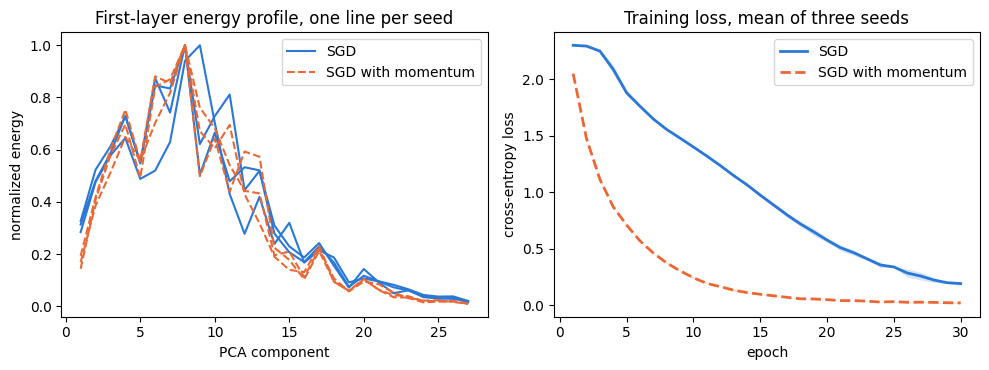

saved /content/CS436-FinalProj-Fork/docs/energy_and_loss.pdf


In [7]:
# color separates the optimizers and the dashed line keeps them apart in a grayscale print
colors = {momentums[0]: '#2a78d6', momentums[1]: '#eb6834'}
line_styles = {momentums[0]: '-', momentums[1]: '--'}
figure_file = PROJECT_DIR / 'docs' / 'energy_and_loss.pdf'

figure, (profile_axis, loss_axis) = plt.subplots(1, 2, figsize=(10, 3.8))
components_axis = np.arange(1, len(profiles[(seeds[0], momentums[0])]) + 1)
epochs_axis = np.arange(1, num_epochs + 1)

for momentum in momentums:
    # one thin line per seed shows how much the profile varies between seeds
    for seed in seeds:
        profile_axis.plot(
            components_axis, profiles[(seed, momentum)], color=colors[momentum],
            linestyle=line_styles[momentum], linewidth=1.5,
            label=labels[momentum] if seed == seeds[0] else None
        )

    # mean loss across the three seeds and shaded by one sample standard deviation
    losses = np.array([
        [epoch['train_loss'] for epoch in results[(seed, momentum)]['history']]
        for seed in seeds
    ])
    mean = losses.mean(axis=0)
    std = losses.std(axis=0, ddof=1)
    loss_axis.plot(epochs_axis, mean, color=colors[momentum],
                   linestyle=line_styles[momentum], linewidth=2, label=labels[momentum])
    loss_axis.fill_between(epochs_axis, mean - std, mean + std,
                           color=colors[momentum], alpha=0.2, linewidth=0)

profile_axis.set_title('First-layer energy profile, one line per seed')
profile_axis.set_xlabel('PCA component')
profile_axis.set_ylabel('normalized energy')
loss_axis.set_title('Training loss, mean of three seeds')
loss_axis.set_xlabel('epoch')
loss_axis.set_ylabel('cross-entropy loss')
profile_axis.legend()
loss_axis.legend()

# save the figure for the report before showing it
figure.tight_layout()
figure.savefig(figure_file)
plt.show()
print(f'saved {figure_file}')

## 7. Findings for the paper

- Momentum raised mean test accuracy from 54.54% to 78.56% which is a gain of 18.84 to 27.34 points on every seed
- Training time did not change so the momentum to SGD ratio is 1.01
- Energy profiles stayed consistent across seeds for both optimizers with correlations of 0.89 to 0.97 for SGD and 0.96 to 0.98 for momentum
- Momentum slightly changed the profile itself 0.95 to 0.99 correlation with SGD on the same seed This agrees with the paper where the first layer learns a consistent profile
- The limitations are SGD had not converged after the 30 epochs so the accuracy gap reflects this fixed budget as well as momentum 
- We used three seeds, one learning rate, one model, and one dataset